# Etapa 1 — EDA + Baseline (Regressão Logística)

**Tech Challenge Fase 1 · FIAP 12MLET · Pipeline Preditivo de Churn em Telecom**

Neste notebook:
1. Entendemos o dataset Telco Customer Churn (volume, qualidade, distribuição das features).
2. Definimos as métricas técnica (F1 / AUC-ROC) e de negócio.
3. Treinamos um **baseline** com Regressão Logística para servir de régua para os modelos da Etapa 2.

> Convenção do projeto: o notebook **explora**; toda função reutilizável mora em `src/churn_alert/` e é importada aqui.
> Analogia web: o notebook é o Postman/REPL; `src/` é o código que vai para produção.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from churn_alert.config import (SEED, RAW_DATA_PATH, MODELS_DIR, DOCS_DIR, TARGET,
                          NUMERIC_FEATURES, CATEGORICAL_FEATURES)
from churn_alert.data import load_raw, clean, split_features_target, train_test_split_stratified
from churn_alert.features import build_pipeline
from churn_alert.evaluate import compute_metrics

np.random.seed(SEED)
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 110
FIG_DIR = DOCS_DIR / "figures"
FIG_DIR.mkdir(exist_ok=True)

print("Seed:", SEED)
print("Dataset:", RAW_DATA_PATH)

Seed: 42
Dataset: C:\Fiap-pos-tech\ML-churn-alert\data\raw\telco_customer_churn.csv


## 1. Visão geral do dataset

Primeiro olhamos o dado **cru**, sem nenhuma transformação, para entender com o que estamos lidando.
Pense no `DataFrame` como um array de objetos JSON (1 linha = 1 cliente) com superpoderes de consulta.

In [2]:
df_raw = load_raw()
print(f"Linhas (clientes): {df_raw.shape[0]:,}  |  Colunas: {df_raw.shape[1]}")
df_raw.head()

Linhas (clientes): 7,043  |  Colunas: 21


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
df_raw.dtypes.to_frame("dtype").T

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
dtype,str,str,int64,str,str,int64,str,str,str,str,...,str,str,str,str,str,str,str,float64,str,str


**Observação importante:** `TotalCharges` aparece como `object` (texto), mas deveria ser número.
Isso é um cheiro de dado sujo. Vamos investigar na seção de qualidade.

In [4]:
df_raw.describe().T

,count,mean,std,min,25%,50%,75%,max
SeniorCitizen,7043.0,0.162147,0.368612,0.00,0.0,0.00,0.00,1.00
tenure,7043.0,32.371149,24.559481,0.00,9.0,29.00,55.00,72.00
MonthlyCharges,7043.0,64.761692,30.090047,18.25,35.5,70.35,89.85,118.75


## 2. Qualidade dos dados

Checamos nulos, duplicados e o problema do `TotalCharges`.

In [5]:
nulos = df_raw.isna().sum()
print("Nulos por coluna (só as que têm):")
print(nulos[nulos > 0] if nulos.sum() else "  nenhum nulo explícito")
print("\nLinhas duplicadas:", df_raw.duplicated().sum())
print("IDs duplicados:", df_raw["customerID"].duplicated().sum())

Nulos por coluna (só as que têm):
  nenhum nulo explícito

Linhas duplicadas: 0
IDs duplicados: 0


In [6]:
# TotalCharges: quantos valores não convertem para número?
tc_num = pd.to_numeric(df_raw["TotalCharges"], errors="coerce")
problema = df_raw[tc_num.isna()]
print(f"Valores de TotalCharges que não são numéricos: {len(problema)}")
print("Valor bruto nesses casos:", repr(problema["TotalCharges"].unique()))
problema[["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Churn"]]

Valores de TotalCharges que não são numéricos: 11
Valor bruto nesses casos: <StringArray>
[' ']
Length: 1, dtype: str


,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,,No
753,3115-CZMZD,0,20.25,,No
936,5709-LVOEQ,0,80.85,,No
1082,4367-NUYAO,0,25.75,,No
1340,1371-DWPAZ,0,56.05,,No
3331,7644-OMVMY,0,19.85,,No
3826,3213-VVOLG,0,25.35,,No
4380,2520-SGTTA,0,20.00,,No
5218,2923-ARZLG,0,19.70,,No
6670,4075-WKNIU,0,73.35,,No


**Diagnóstico:** os 11 clientes com `TotalCharges` em branco têm `tenure = 0`, ou seja, acabaram de entrar
e ainda não pagaram nenhuma fatura. O valor economicamente correto é **0**, não a média. Essa regra está
implementada em `churn_alert.data.clean()`.

## 3. A variável alvo: `Churn`

O que queremos prever. A proporção entre as classes define **como** devemos avaliar o modelo.

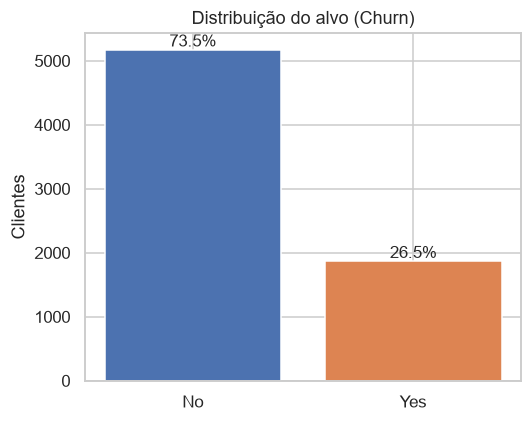

Churn
No     73.46
Yes    26.54


In [7]:
churn_counts = df_raw[TARGET].value_counts()
churn_pct = df_raw[TARGET].value_counts(normalize=True) * 100

fig, ax = plt.subplots(figsize=(5, 4))
bars = ax.bar(churn_counts.index, churn_counts.values, color=["#4C72B0", "#DD8452"])
for b, p in zip(bars, churn_pct.values):
    ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 50, f"{p:.1f}%", ha="center", fontsize=11)
ax.set_title("Distribuição do alvo (Churn)")
ax.set_ylabel("Clientes")
ax.set_xlabel("")
plt.tight_layout()
plt.savefig(FIG_DIR / "01_target_distribution.png")
plt.show()

print(churn_pct.round(2).to_string())

**Conclusão:** cerca de **26,5%** dos clientes cancelam. As classes são desbalanceadas.

Consequência prática: um modelo "burro" que sempre responde *"não vai cancelar"* acerta ~73,5% das vezes.
Portanto **acurácia não serve** como métrica principal. Vamos provar isso numericamente mais abaixo.

## 4. Features numéricas vs. churn

`tenure` (meses de casa), `MonthlyCharges` (mensalidade) e `TotalCharges` (total pago).
Olhamos a distribuição de cada uma separando quem saiu de quem ficou.

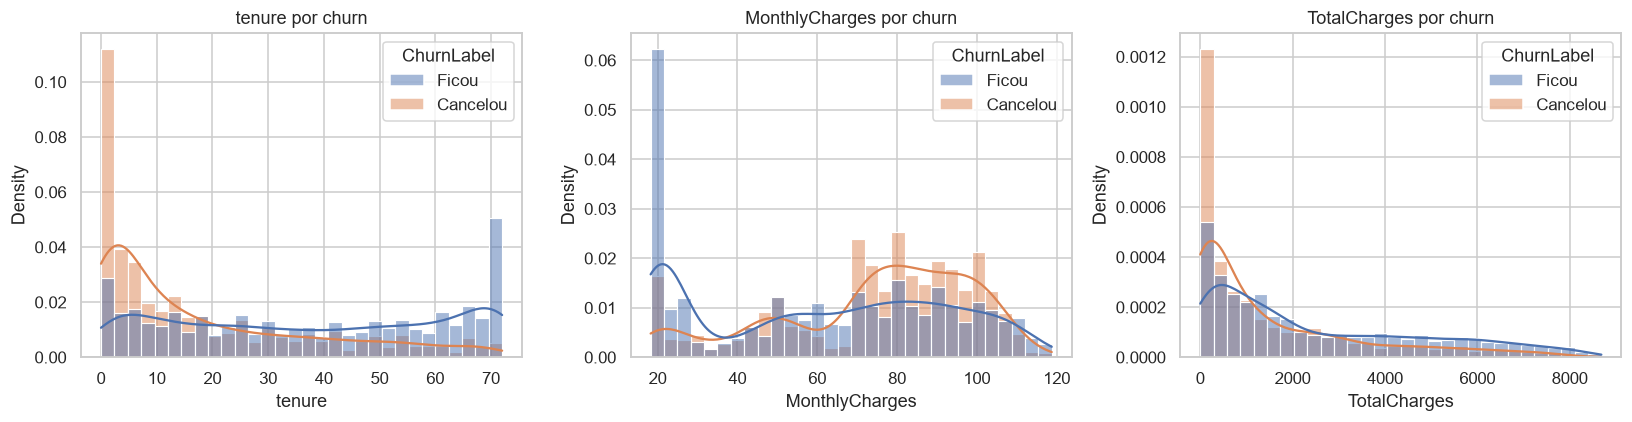

In [8]:
df_eda = clean(df_raw)
df_eda["ChurnLabel"] = df_eda[TARGET].map({0: "Ficou", 1: "Cancelou"})

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ["tenure", "MonthlyCharges", "TotalCharges"]):
    sns.histplot(data=df_eda, x=col, hue="ChurnLabel", bins=30, kde=True,
                 stat="density", common_norm=False, ax=ax, alpha=0.5)
    ax.set_title(f"{col} por churn")
plt.tight_layout()
plt.savefig(FIG_DIR / "02_numeric_by_churn.png")
plt.show()

**Leitura dos gráficos:**
- `tenure`: quem cancela está concentrado nos **primeiros meses**. Cliente antigo raramente sai.
- `MonthlyCharges`: quem cancela paga, em média, **mensalidades mais altas** (pico em torno de 70–100).
- `TotalCharges`: consequência das duas anteriores; quem sai pagou pouco no total porque ficou pouco tempo.

Esses três fatos sozinhos já sugerem uma história de negócio: *clientes novos com plano caro são o grupo de risco*.

## 5. Features categóricas: taxa de churn por categoria

Para cada coluna de texto, calculamos a % de churn dentro de cada valor. Barras acima da linha tracejada
(média geral) indicam categorias de **maior risco**.

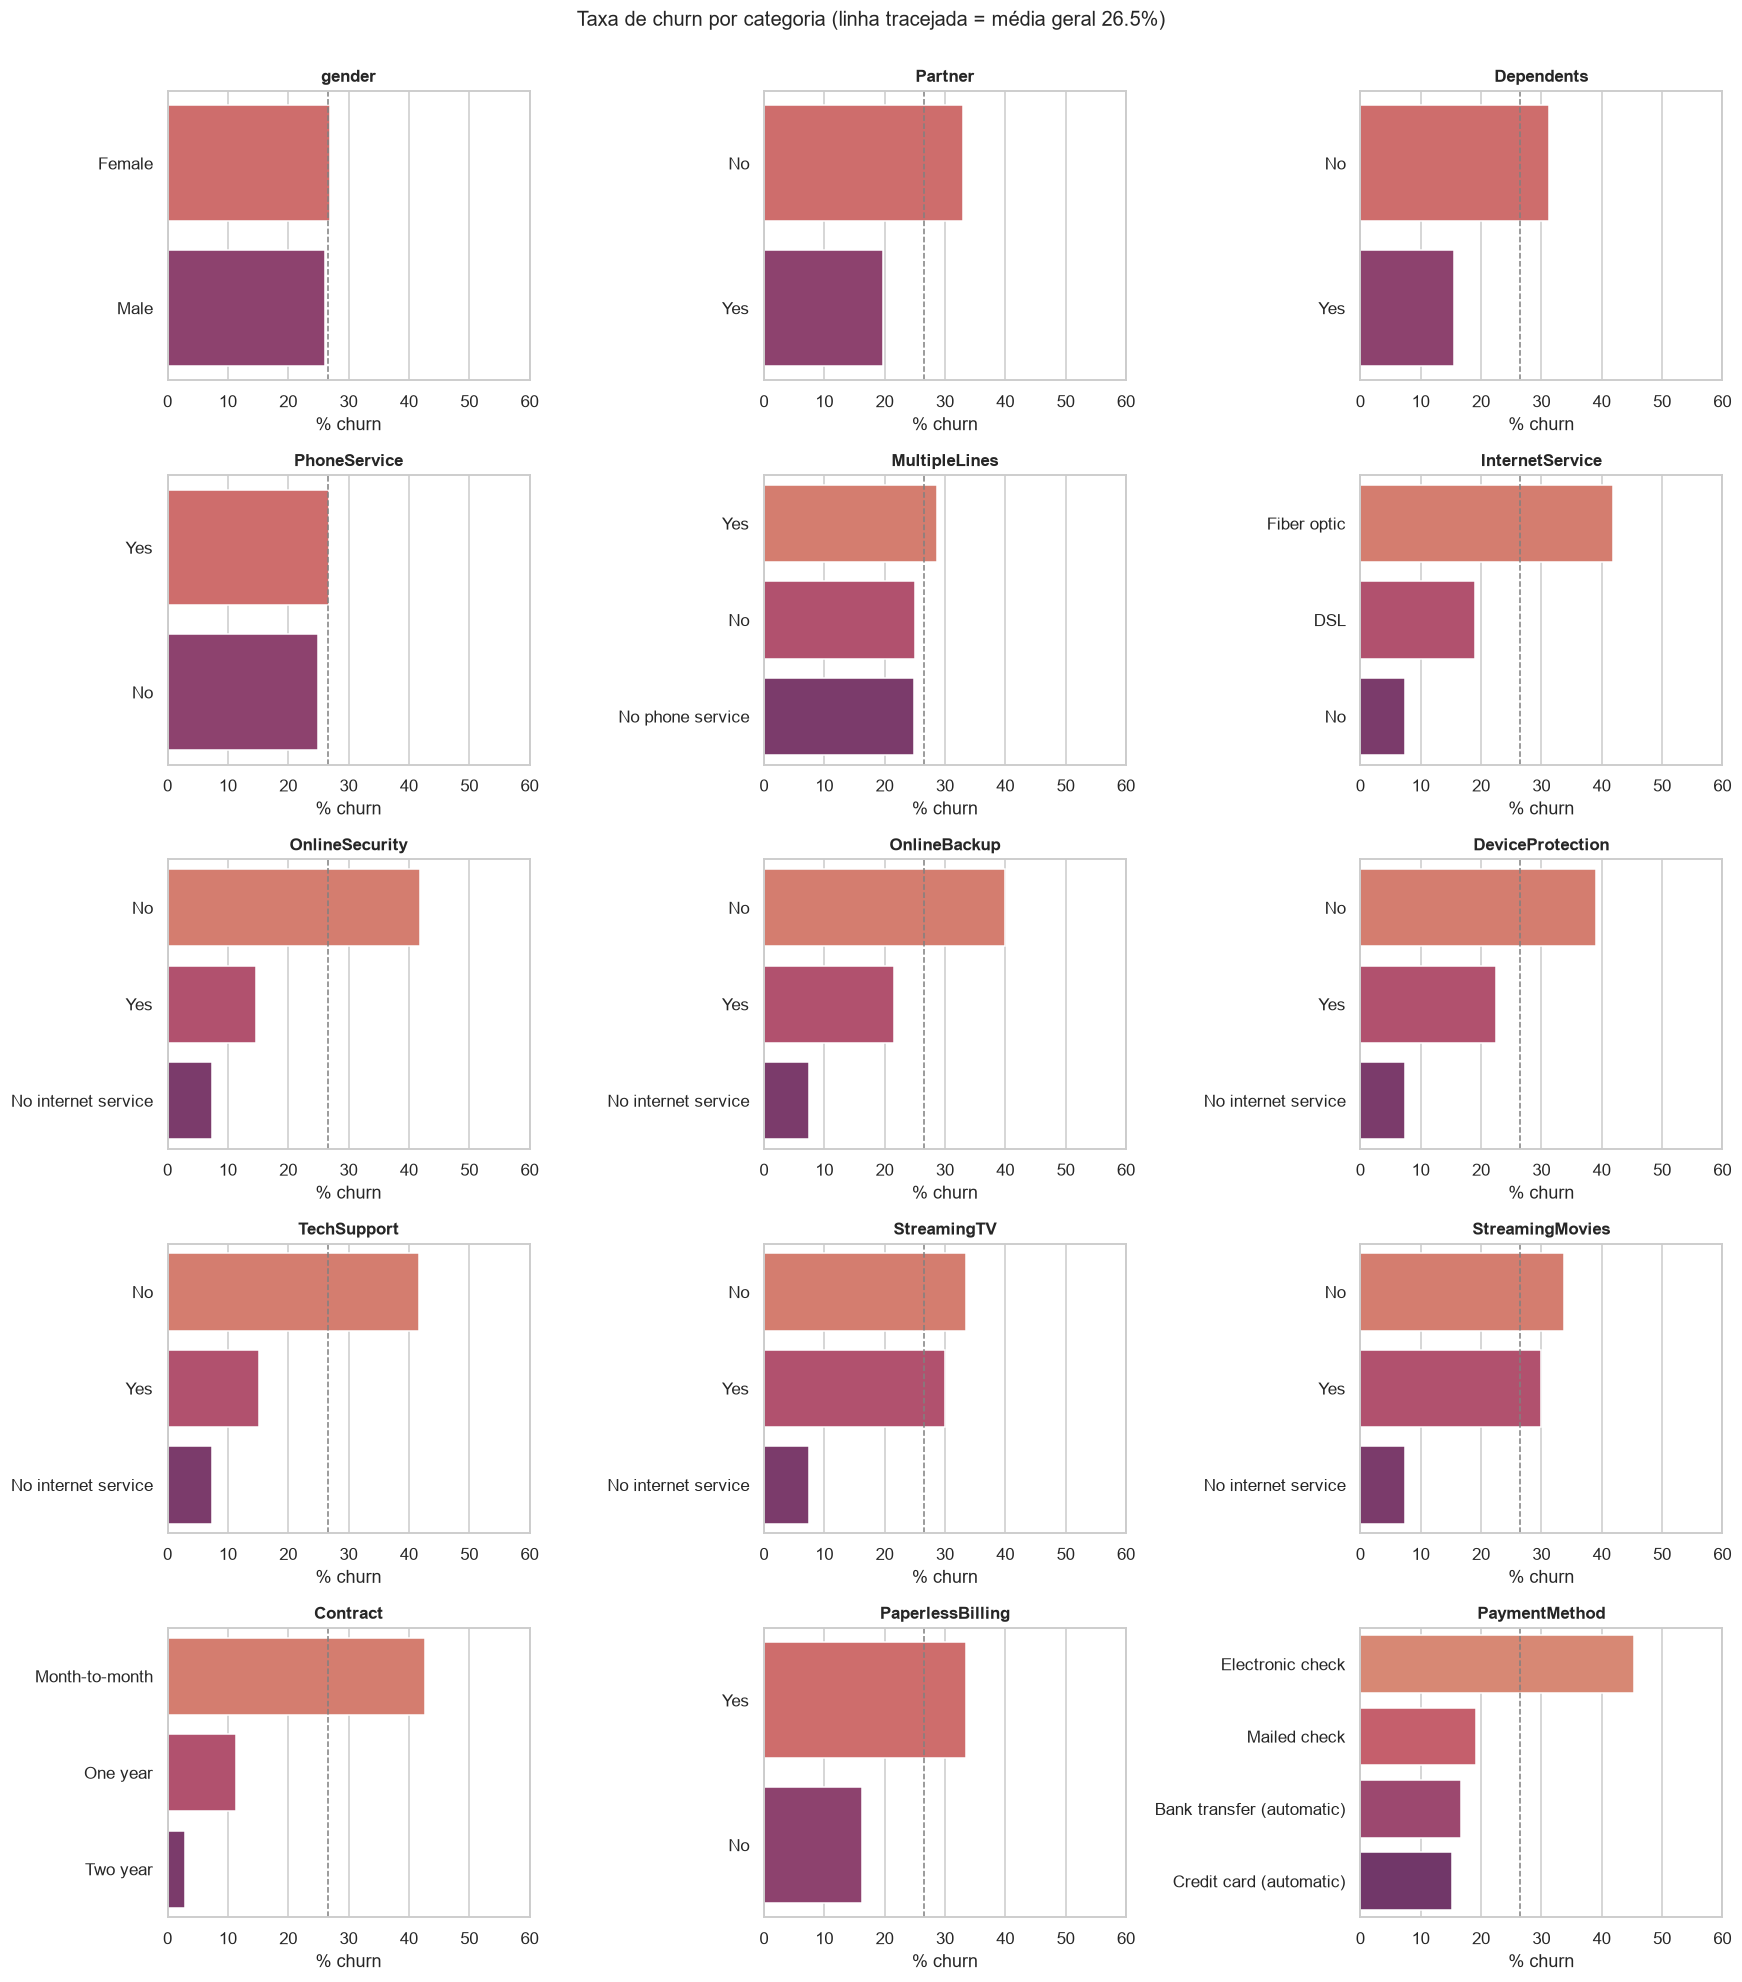

In [9]:
media_geral = df_eda[TARGET].mean() * 100
cat_cols = [c for c in CATEGORICAL_FEATURES]

fig, axes = plt.subplots(5, 3, figsize=(16, 18))
for ax, col in zip(axes.flat, cat_cols):
    taxa = df_eda.groupby(col)[TARGET].mean().mul(100).sort_values(ascending=False)
    sns.barplot(x=taxa.values, y=taxa.index, ax=ax, hue=taxa.index, legend=False, palette="flare")
    ax.axvline(media_geral, ls="--", color="gray", lw=1)
    ax.set_title(col, fontsize=11, fontweight="bold")
    ax.set_xlabel("% churn")
    ax.set_ylabel("")
    ax.set_xlim(0, 60)
plt.suptitle(f"Taxa de churn por categoria (linha tracejada = média geral {media_geral:.1f}%)", y=1.0, fontsize=13)
plt.tight_layout()
plt.savefig(FIG_DIR / "03_churn_rate_by_category.png", bbox_inches="tight")
plt.show()

In [10]:
# Ranking: as categorias com maior taxa de churn em todo o dataset
linhas = []
for col in cat_cols:
    taxa = df_eda.groupby(col)[TARGET].agg(["mean", "size"])
    for val, row in taxa.iterrows():
        linhas.append({"feature": col, "categoria": val, "churn_%": round(row["mean"] * 100, 1), "clientes": int(row["size"])})
ranking = pd.DataFrame(linhas).sort_values("churn_%", ascending=False)
ranking.head(10)

,feature,categoria,churn_%,clientes
39,PaymentMethod,Electronic check,45.3,2365
32,Contract,Month-to-month,42.7,3875
12,InternetService,Fiber optic,41.9,3096
14,OnlineSecurity,No,41.8,3498
23,TechSupport,No,41.6,3473
17,OnlineBackup,No,39.9,3088
20,DeviceProtection,No,39.1,3095
29,StreamingMovies,No,33.7,2785
36,PaperlessBilling,Yes,33.6,4171
26,StreamingTV,No,33.5,2810


**Principais sinais de risco encontrados:**
- `Contract = Month-to-month` → ~43% de churn (vs. ~3% em contratos de 2 anos). É o fator mais forte.
- `InternetService = Fiber optic` → ~42%. Fibra é o serviço mais caro; pode indicar insatisfação com preço/qualidade.
- `PaymentMethod = Electronic check` → ~45%. Pagamento manual sem débito automático facilita o cancelamento.
- Ausência de `OnlineSecurity` / `TechSupport` → ~41%. Clientes sem serviços de suporte estão menos "presos".
- `gender` praticamente **não influencia** (~26% em ambos). Bom sinal do ponto de vista de viés.

## 6. Correlação entre numéricas

Correlação alta entre features (multicolinearidade) atrapalha a interpretação dos coeficientes da regressão logística.

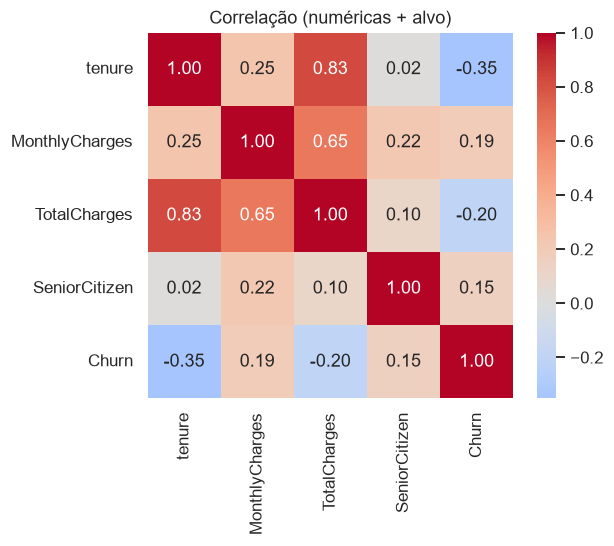

In [11]:
corr = df_eda[NUMERIC_FEATURES + [TARGET]].corr()
fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax, square=True)
ax.set_title("Correlação (numéricas + alvo)")
plt.tight_layout()
plt.savefig(FIG_DIR / "04_correlation.png")
plt.show()

`TotalCharges` tem correlação forte com `tenure` (≈0,83), o que é esperado: total ≈ tenure × mensalidade.
Mantemos as três por enquanto (o baseline usa regularização L2, que lida bem com isso), mas é um ponto a
revisitar se quisermos interpretar coeficientes com rigor.

## 7. Definição das métricas

| Tipo | Métrica | Por quê |
|---|---|---|
| **Técnica principal** | **F1-score (classe churn)** | Equilibra precision (não desperdiçar oferta) e recall (não deixar cliente escapar). Robusta ao desbalanceamento. |
| Técnica complementar | AUC-ROC | Mede a qualidade do *ranking* de risco, independente do limiar de 0,5. Útil para priorizar a lista do time de retenção. |
| Acompanhamento | Recall, Precision, Acurácia | Para explicar o trade-off ao negócio. |
| **Negócio** | Churn mensal da carteira abordada; receita retida ÷ custo de campanha | Definidas no [ML Canvas](../docs/ml_canvas.md). |

**Regra de ouro:** o modelo campeão da Etapa 2 precisa vencer o baseline em **F1 com validação cruzada**.

## 8. Preparação: limpeza + split estratificado

Separamos 20% para teste **antes** de qualquer ajuste do modelo. O split é estratificado para que a proporção de
churn seja a mesma no treino e no teste. O conjunto de teste só será tocado para a avaliação final.

In [12]:
df = clean(df_raw)
X, y = split_features_target(df)
X_train, X_test, y_train, y_test = train_test_split_stratified(X, y, test_size=0.2, seed=SEED)

print(f"Treino: {len(X_train):,} clientes ({y_train.mean():.1%} churn)")
print(f"Teste : {len(X_test):,} clientes ({y_test.mean():.1%} churn)")
print(f"Features: {X.shape[1]} ({len(NUMERIC_FEATURES)} numéricas + {len(CATEGORICAL_FEATURES)} categóricas)")

Treino: 5,634 clientes (26.5% churn)
Teste : 1,409 clientes (26.5% churn)
Features: 19 (4 numéricas + 15 categóricas)


## 9. Baseline "burro": prever sempre a classe majoritária

Antes de qualquer modelo real, medimos o pior caso útil. Isso prova por que acurácia engana.

In [13]:
from sklearn.dummy import DummyClassifier

dummy = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
m_dummy = compute_metrics(y_test, dummy.predict(X_test), dummy.predict_proba(X_test)[:, 1])
pd.Series(m_dummy, name="Dummy (sempre 'não')").to_frame().T.round(3)

,accuracy,precision,recall,f1,roc_auc
Dummy (sempre 'não'),0.735,0.0,0.0,0.0,0.5


Acurácia de ~73% com **F1 = 0** e **recall = 0**: o modelo não encontra nenhum cliente em risco.
Qualquer coisa que entregarmos precisa ser julgada contra isso, não contra "0%".

## 10. Baseline real: Regressão Logística

**O que é:** um modelo linear que calcula um "score" somando cada feature multiplicada por um peso,
e passa o score por uma função sigmoide para virar probabilidade entre 0 e 1.

**Analogia web:** é como um sistema de pontuação de spam: cada palavra soma ou subtrai pontos, e no fim
você converte os pontos numa probabilidade. Os pesos são aprendidos dos dados em vez de escritos à mão.

**Por que começar por ele:** rápido, estável, interpretável (dá para ler os pesos) e difícil de bater em dados tabulares pequenos.

O `Pipeline` abaixo junta pré-processamento (`StandardScaler` + `OneHotEncoder`) e modelo num único objeto.
Usamos `class_weight="balanced"` para que o modelo dê mais importância à classe minoritária (churn).

In [14]:
from sklearn.linear_model import LogisticRegression

baseline = build_pipeline(
    LogisticRegression(max_iter=1000, class_weight="balanced", random_state=SEED)
)
baseline.fit(X_train, y_train)

y_pred = baseline.predict(X_test)
y_proba = baseline.predict_proba(X_test)[:, 1]
m_base = compute_metrics(y_test, y_pred, y_proba)

comparativo = pd.DataFrame([m_dummy, m_base], index=["Dummy (majoritária)", "Regressão Logística"]).round(3)
comparativo

,accuracy,precision,recall,f1,roc_auc
Dummy (majoritária),0.735,0.000,0.000,0.000,0.500
Regressão Logística,0.738,0.504,0.783,0.614,0.842


## 11. Diagnóstico do baseline: matriz de confusão e curva ROC

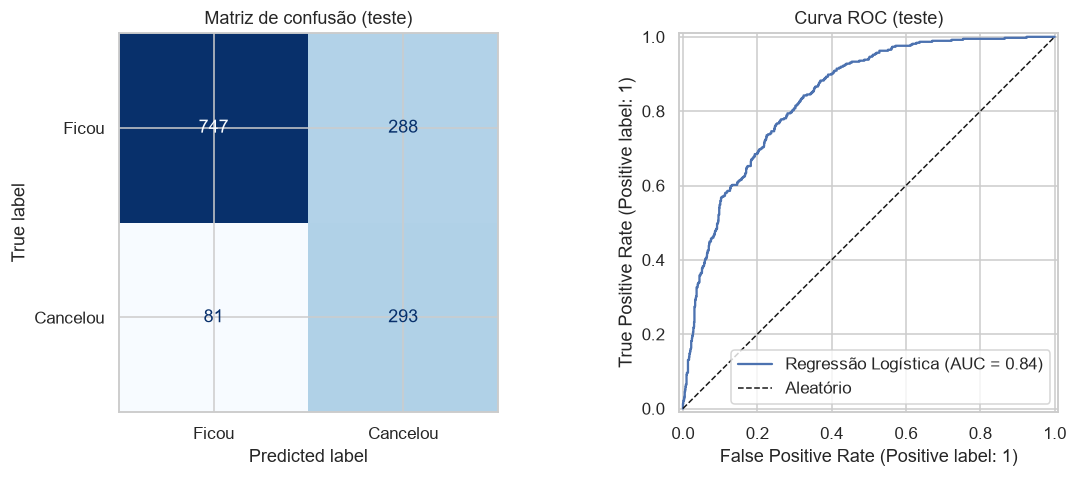

In [15]:
from sklearn.metrics import ConfusionMatrixDisplay, RocCurveDisplay

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=["Ficou", "Cancelou"],
                                        cmap="Blues", ax=axes[0], colorbar=False)
axes[0].set_title("Matriz de confusão (teste)")
RocCurveDisplay.from_predictions(y_test, y_proba, name="Regressão Logística", ax=axes[1])
axes[1].plot([0, 1], [0, 1], "k--", lw=1, label="Aleatório")
axes[1].legend()
axes[1].set_title("Curva ROC (teste)")
plt.tight_layout()
plt.savefig(FIG_DIR / "05_baseline_confusion_roc.png")
plt.show()

**Como ler a matriz de confusão:**
- Linha = realidade, coluna = previsão.
- Canto inferior direito = churns que o modelo **pegou** (verdadeiros positivos). Esse número ÷ total de churns reais = recall.
- Canto superior direito = clientes que ficariam mas o modelo marcou como risco (falsos positivos). Custam uma oferta desnecessária.

Com `class_weight="balanced"`, o baseline troca precision por recall de propósito: para o negócio, deixar
um cliente sair custa mais do que oferecer um desconto a quem ficaria.

## 12. O que o modelo aprendeu: pesos (coeficientes)

Coeficiente positivo → aumenta a chance de churn. Negativo → diminui. Como as features estão padronizadas,
podemos comparar magnitudes.

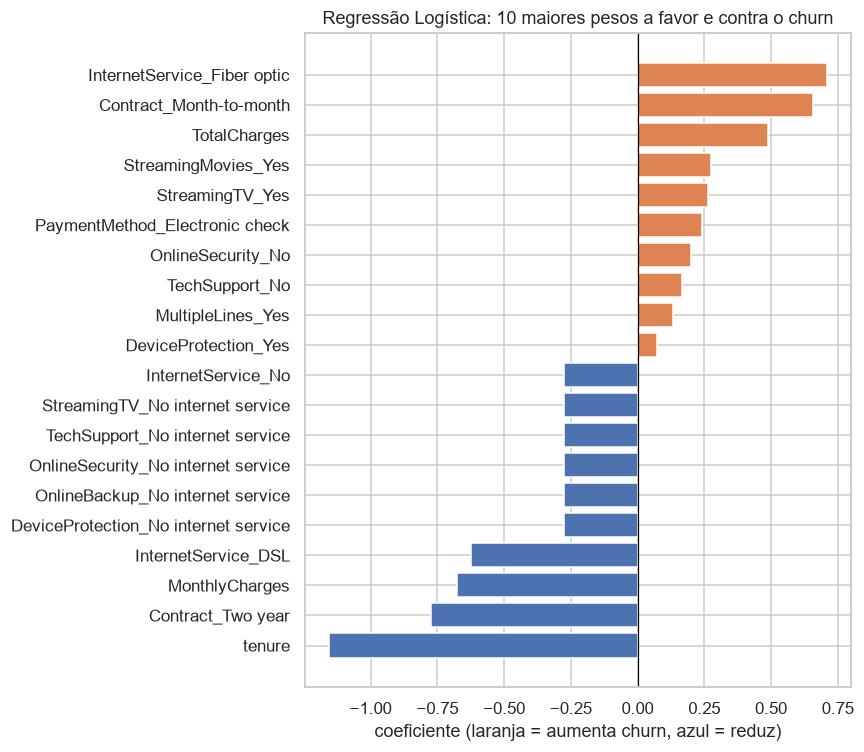

In [16]:
feature_names = baseline.named_steps["preprocessor"].get_feature_names_out()
coefs = pd.Series(baseline.named_steps["model"].coef_[0], index=feature_names).sort_values()

top = pd.concat([coefs.head(10), coefs.tail(10)])
fig, ax = plt.subplots(figsize=(8, 7))
colors = ["#DD8452" if v > 0 else "#4C72B0" for v in top.values]
ax.barh(top.index, top.values, color=colors)
ax.axvline(0, color="black", lw=0.8)
ax.set_title("Regressão Logística: 10 maiores pesos a favor e contra o churn")
ax.set_xlabel("coeficiente (laranja = aumenta churn, azul = reduz)")
plt.tight_layout()
plt.savefig(FIG_DIR / "06_baseline_coefficients.png")
plt.show()

Os pesos confirmam a EDA: contrato mensal, fibra óptica e cheque eletrônico empurram para o churn;
`tenure` alto e contrato de 2 anos seguram o cliente. O modelo "descobriu" sozinho o que vimos nos gráficos,
o que dá confiança de que não há vazamento nem bug grosseiro.

**Armadilha clássica (cai em prova):** `MonthlyCharges` aparece com peso *negativo* embora a EDA mostre que quem paga
mais cancela mais. Isso acontece por **multicolinearidade**: `TotalCharges ≈ tenure × MonthlyCharges`, então as três
features disputam o mesmo sinal e a regressão redistribui os pesos entre elas de forma pouco intuitiva. O modelo
continua prevendo bem (o conjunto dos três pesos está certo), mas **ler um coeficiente isolado nesse cenário engana**.
Soluções possíveis na Etapa 2: remover `TotalCharges`, ou usar modelos de árvore, que não sofrem desse problema.

## 13. Robustez: validação cruzada (5 folds)

Um único split pode dar sorte ou azar. A validação cruzada treina 5 vezes em fatias diferentes do treino e
reporta média ± desvio. Esse será o **número oficial** para comparar modelos na Etapa 2.

In [17]:
from sklearn.model_selection import StratifiedKFold, cross_validate

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
scores = cross_validate(baseline, X_train, y_train, cv=cv,
                        scoring=["f1", "roc_auc", "recall", "precision"], n_jobs=1)
cv_resumo = {k.replace("test_", ""): f"{v.mean():.3f} ± {v.std():.3f}"
             for k, v in scores.items() if k.startswith("test_")}
pd.Series(cv_resumo, name="Regressão Logística (CV 5-fold, treino)").to_frame()

,"Regressão Logística (CV 5-fold, treino)"
f1,0.628 ± 0.023
roc_auc,0.846 ± 0.012
recall,0.801 ± 0.038
precision,0.517 ± 0.019


## 14. Salvar o baseline e registrar o experimento

O artefato `.joblib` contém o pipeline inteiro (pré-processamento + modelo). É ele que a API vai carregar na Etapa 3.
O registro em `docs/experimentos.md` é o nosso "log de experimentos" simples, exigido pelo enunciado.

In [18]:
import joblib
from datetime import date

MODELS_DIR.mkdir(exist_ok=True)
model_path = MODELS_DIR / "baseline_logreg.joblib"
joblib.dump(baseline, model_path)
print("Modelo salvo em:", model_path)

registro = {
    "data": date.today().isoformat(),
    "etapa": "1",
    "modelo": "LogisticRegression(class_weight=balanced, C=1.0)",
    "cv_f1": f"{scores['test_f1'].mean():.3f} ± {scores['test_f1'].std():.3f}",
    "cv_roc_auc": f"{scores['test_roc_auc'].mean():.3f} ± {scores['test_roc_auc'].std():.3f}",
    "teste_f1": f"{m_base['f1']:.3f}",
    "teste_roc_auc": f"{m_base['roc_auc']:.3f}",
    "teste_recall": f"{m_base['recall']:.3f}",
    "teste_precision": f"{m_base['precision']:.3f}",
    "artefato": model_path.name,
}

exp_path = DOCS_DIR / "experimentos.md"
header = "| " + " | ".join(registro.keys()) + " |\n|" + "---|" * len(registro) + "\n"
linha = "| " + " | ".join(str(v) for v in registro.values()) + " |\n"
if not exp_path.exists():
    exp_path.write_text("# Registro de experimentos\n\n" + header + linha, encoding="utf-8")
else:
    conteudo = exp_path.read_text(encoding="utf-8")
    if linha not in conteudo:
        exp_path.write_text(conteudo + linha, encoding="utf-8")
print(exp_path.read_text(encoding="utf-8"))

Modelo salvo em: C:\Fiap-pos-tech\ML-churn-alert\models\baseline_logreg.joblib
# Registro de experimentos

| data | etapa | modelo | cv_f1 | cv_roc_auc | teste_f1 | teste_roc_auc | teste_recall | teste_precision | artefato |
|---|---|---|---|---|---|---|---|---|---|
| 2026-10-21 | 1 | LogisticRegression(class_weight=balanced, C=1.0) | 0.628 ± 0.023 | 0.846 ± 0.012 | 0.614 | 0.842 | 0.783 | 0.504 | baseline_logreg.joblib |



## 15. Conclusões da Etapa 1

**Sobre os dados**
- 7.043 clientes, 20 features úteis, sem nulos explícitos; único problema real foi `TotalCharges` em texto (11 clientes novos).
- Alvo desbalanceado (~26,5% churn) → F1 e AUC-ROC como métricas, acurácia só para contexto.
- Fatores de risco claros: contrato mensal, fibra óptica, cheque eletrônico, pouco tempo de casa, mensalidade alta, ausência de suporte/segurança.

**Sobre o baseline**
- Regressão Logística com pesos balanceados já entrega um ranking de risco decente (AUC ≈ 0,84) e recall alto.
- Os pesos aprendidos são coerentes com a EDA, sinal de que o pipeline está correto.

**Próximos passos (Etapa 2)**
- Treinar Random Forest e MLPClassifier com o **mesmo** pré-processamento e **mesma** validação cruzada.
- Comparar F1 (CV) contra o baseline e escolher o campeão.
- Experimentar ajuste de limiar de decisão para otimizar o trade-off precision/recall conforme o custo de negócio.